# Task 2: EDA and Data Quality Assessment

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from collections import Counter

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# We only READ the raw file. We never save back to data/raw/
df = pd.read_csv("../data/raw/ted_talks.csv")

# Work on a copy so the original stays untouched
data = df.copy()
print("Loaded:", data.shape)

Loaded: (4005, 19)


In [2]:
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])
print()
print(data.dtypes)

Rows: 4005
Columns: 19

talk_id             int64
title                 str
speaker_1             str
all_speakers          str
occupations           str
about_speakers        str
views               int64
recorded_date         str
published_date        str
event                 str
native_lang           str
available_lang        str
comments          float64
duration            int64
topics                str
related_talks         str
url                   str
description           str
transcript            str
dtype: object


In [3]:
# Numeric columns (mean, median = 50%, min, max)
display(data.describe())

# Text columns (count, unique, most frequent value)
display(data.describe(include="object"))

,talk_id,views,comments,duration
count,4005.000000,4.005000e+03,3350.000000,4005.000000
mean,12432.538327,2.148006e+06,161.997015,724.011236
std,17447.576262,3.451226e+06,268.838922,361.775462
min,1.000000,0.000000e+00,0.000000,60.000000
25%,1252.000000,8.820690e+05,38.000000,393.000000
50%,2333.000000,1.375508e+06,89.000000,738.000000
75%,23777.000000,2.133110e+06,188.000000,974.000000
max,62794.000000,6.505195e+07,6449.000000,3922.000000


C:\Users\oop\AppData\Local\Temp\ipykernel_12848\1179636557.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(data.describe(include="object"))


,title,speaker_1,all_speakers,occupations,about_speakers,recorded_date,published_date,event,native_lang,available_lang,topics,related_talks,url,description,transcript
count,4005,4005,4001,3483,3502,4004,4005,4005,4005,4005,4005,4005,4005,4005,4005
unique,4005,3274,3306,2049,2977,1334,2962,459,12,3902,3977,4005,4005,4005,4005
top,Averting the climate crisis,Alex Gendler,{0: 'Alex Gendler'},{0: ['writer']},{0: 'Alex Rosenthal takes everyday experiences...,2017-04-24,2017-09-07,TED-Ed,en,['en'],"['TED-Ed', 'math']","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
freq,1,34,34,53,10,97,27,556,3957,24,8,1,1,1,1


In [4]:
for col in ["talk_id", "url", "title"]:
    if col in data.columns:
        print(f"Unique {col}: {data[col].nunique()} out of {len(data)}")
    else:
        print(f"Column '{col}' is not available in this dataset")

Unique talk_id: 4005 out of 4005
Unique url: 4005 out of 4005
Unique title: 4005 out of 4005


## Activity 1: Dataset Summary, Observations

### Size
- Rows: **4005** (each row is one TED talk)
- Columns: **19**

### Column names and data types

| Data type | Columns |
|---|---|
| int64 (whole numbers) | `talk_id`, `views`, `duration` |
| float64 (decimal numbers) | `comments` |
| str (text) | `title`, `speaker_1`, `all_speakers`, `occupations`, `about_speakers`, `recorded_date`, `published_date`, `event`, `native_lang`, `available_lang`, `topics`, `related_talks`, `url`, `description`, `transcript` |

(The `dtype: object` line at the bottom of the output is how pandas labels the text columns.)

### Unique talks
Every row has a unique `talk_id`, so the dataset contains **4005 unique talks**. `url` and `title` are also fully unique (checked in Activity 2).

### Descriptive statistics
- The numeric columns are `talk_id`, `views`, `comments` and `duration`. Their statistics are analysed in detail in Activity 5.
- `talk_id` is only an identifier, so its mean and median have no real meaning.
- For the text columns (`description`, `transcript`), lengths and word counts are analysed in Activity 3.

### Observations about data types
1. **Dates are stored as text.** `recorded_date` and `published_date` are `str`, not datetime. They would need converting (for example with `pd.to_datetime`) before any date-based analysis, such as finding the newest talks.
2. **`comments` is float64**, not int. This is because it contains missing values (NaN), which force pandas to use decimals. This is a side effect of the missing data (655 missing values).
3. **List-like and dictionary-like columns are stored as text.** `topics` and `available_lang` look like lists (for example `['ar', 'bg', 'cs']`), while `all_speakers` and `related_talks` look like dictionaries (for example `{0: 'Al Gore'}`). All of them are plain text strings, so they need parsing before use. The `topics` column is handled in Activity 4.
4. **Numeric columns have sensible types.** `views` and `duration` are whole numbers, as expected.

In [5]:
missing = pd.DataFrame({
    "missing_count": data.isnull().sum(),
    "missing_percent": (data.isnull().sum() / len(data) * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing)

,missing_count,missing_percent
comments,655,16.35
occupations,522,13.03
about_speakers,503,12.56
all_speakers,4,0.10
recorded_date,1,0.02
talk_id,0,0.00
title,0,0.00
speaker_1,0,0.00
views,0,0.00
event,0,0.00


In [6]:
print("Fully duplicate rows:", data.duplicated().sum())

for col in ["talk_id", "url", "title"]:
    if col in data.columns:
        print(f"Repeated {col}:", data[col].duplicated().sum())

Fully duplicate rows: 0
Repeated talk_id: 0
Repeated url: 0
Repeated title: 0


In [7]:
def count_empty(series):
    return series.isnull().sum() + (series.astype(str).str.strip() == "").where(series.notnull(), False).sum()

key_fields = ["title", "description", "topics", "transcript", "url"]
rows = []
for col in key_fields:
    if col in data.columns:
        rows.append({"column": col, "missing_or_empty": int(count_empty(data[col]))})
    else:
        rows.append({"column": col, "missing_or_empty": "COLUMN NOT AVAILABLE"})
display(pd.DataFrame(rows))

,column,missing_or_empty
0,title,0
1,description,0
2,topics,0
3,transcript,0
4,url,0


## Activity 2: Missing Values and Duplicates, Findings and Impact on the Recommendation System

### What I found (4005 talks, 19 columns)

**Duplicates:** There are no duplicate rows, no repeated `talk_id`, no repeated `url` and no repeated `title`. Every talk appears exactly once.

**Key fields:** `title`, `description`, `topics`, `transcript` and `url` have 0 missing or empty values.

**Columns with missing values:**

| Column | Missing count | Missing % |
|---|---|---|
| comments | 655 | 16.35% |
| occupations | 522 | 13.03% |
| about_speakers | 503 | 12.56% |
| all_speakers | 4 | 0.10% |
| recorded_date | 1 | 0.02% |

The other 14 columns have no missing values.

### Which missing fields may affect the recommendation system

| Field | Role in the recommender | Impact |
|---|---|---|
| transcript, description, topics | Core features for content-based filtering (text similarity and tag matching) | **None.** These are 100% complete, so every talk can be compared. |
| title, url | Shown to the user and used to open the talk in the Streamlit app | **None.** Complete. |
| comments (16.35% missing) | Possible popularity or engagement signal | **Medium.** About 1 in 6 talks has no comment count. If used for ranking, these talks could be unfairly treated as "less engaging". |
| occupations (13.03%), about_speakers (12.56%) | Optional speaker information that could add extra features | **Low.** The core model doesn't depend on them, but speaker-based features would be incomplete. |
| all_speakers (0.10%) | Alternative speaker list | **Very low.** `speaker_1` is complete, so the main speaker is always known. |
| recorded_date (0.02%) | Used for time-based or recency analysis | **Very low.** Only 1 talk is affected. |

### Proposed handling strategy (nothing has been deleted yet)

1. **comments:** Do not fill with 0, because that would claim the talk had no comments. Keep as missing for now. If it is used as a feature later, fill with the median and add a flag column `comments_missing`.
2. **occupations and about_speakers:** Fill with the label "Unknown". They are optional features, so we don't need to remove any talks.
3. **all_speakers:** Fill the 4 missing values from `speaker_1`, since the main speaker is already known.
4. **recorded_date:** Check the single missing row manually. If it can't be recovered, leave it as missing, because one row has almost no effect.
5. **Duplicates:** No action needed. After the cleaning phase, I will re-check that the cleaning steps did not create any duplicates.
6. **Note:** The core text fields (`transcript`, `description`, `topics`) need no missing-value fixing. The cleaning effort should go into text preprocessing, which is the next task.

In [8]:
text_cols = [c for c in ["transcript", "description"] if c in data.columns]
missing_text_cols = [c for c in ["transcript", "description"] if c not in data.columns]
if missing_text_cols:
    print("Not available in dataset:", missing_text_cols)

for col in text_cols:
    data[f"{col}_chars"] = data[col].fillna("").astype(str).str.len()
    data[f"{col}_words"] = data[col].fillna("").astype(str).str.split().str.len()

summary_cols = [c for c in data.columns if c.endswith("_chars") or c.endswith("_words")]
display(data[summary_cols].describe())

,transcript_chars,transcript_words,description_chars,description_words
count,4005.000000,4005.000000,4005.000000,4005.000000
mean,10032.016729,1796.845693,353.283895,58.195506
std,5490.739801,1004.008431,115.615611,19.430348
min,18.000000,2.000000,52.000000,9.000000
25%,5185.000000,928.000000,259.000000,43.000000
50%,9840.000000,1753.000000,349.000000,57.000000
75%,13632.000000,2445.000000,434.000000,72.000000
max,60615.000000,11121.000000,907.000000,143.000000


In [9]:
# Thresholds are my starting choice. Change them if the data suggests otherwise.
SHORT_TRANSCRIPT_WORDS = 200
SHORT_DESCRIPTION_WORDS = 10

if "transcript_words" in data.columns:
    print("Empty transcripts:", (data["transcript_words"] == 0).sum())
    print(f"Transcripts under {SHORT_TRANSCRIPT_WORDS} words:",
          (data["transcript_words"] < SHORT_TRANSCRIPT_WORDS).sum())
    display(data.nsmallest(5, "transcript_words")[["title", "transcript_words"]])

if "description_words" in data.columns:
    print("Empty descriptions:", (data["description_words"] == 0).sum())
    print(f"Descriptions under {SHORT_DESCRIPTION_WORDS} words:",
          (data["description_words"] < SHORT_DESCRIPTION_WORDS).sum())

Empty transcripts: 0
Transcripts under 200 words: 28


,title,transcript_words
1825,"A dance in a hurricane of paper, wind and light",2
145,My magic moves,3
904,"On violin and cello, ""Passacaglia""",4
1393,"Dance, tiny robots!",4
1948,An 11-year-old prodigy performs old-school jazz,4


Empty descriptions: 0
Descriptions under 10 words: 1


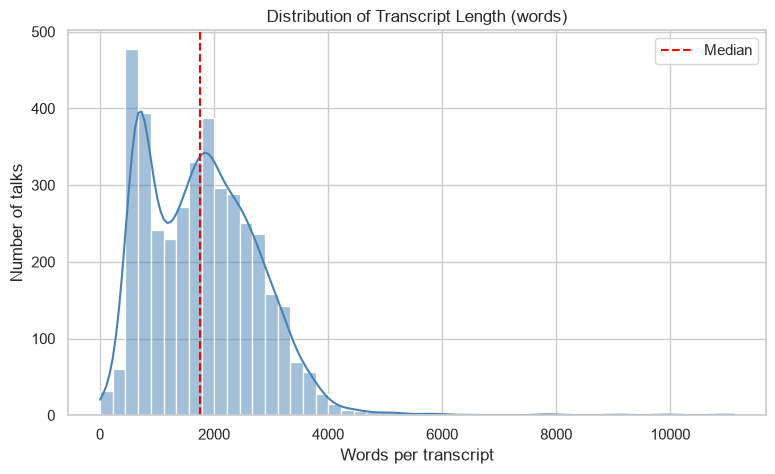

In [10]:
if "transcript_words" in data.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(data["transcript_words"], bins=50, kde=True, color="steelblue")
    plt.axvline(data["transcript_words"].median(), color="red", linestyle="--", label="Median")
    plt.title("Distribution of Transcript Length (words)")
    plt.xlabel("Words per transcript")
    plt.ylabel("Number of talks")
    plt.legend()
    plt.show()

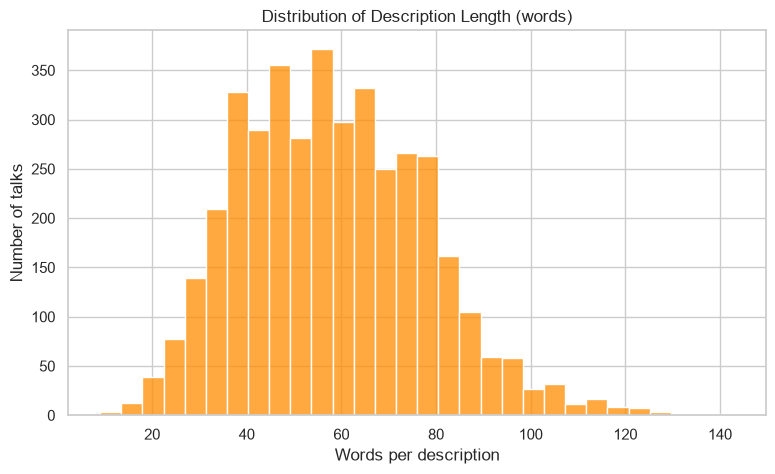

In [11]:
if "description_words" in data.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(data["description_words"], bins=30, color="darkorange")
    plt.title("Distribution of Description Length (words)")
    plt.xlabel("Words per description")
    plt.ylabel("Number of talks")
    plt.show()

## Activity 3: Text Analysis, Observations

**Columns used:** `transcript` and `description` are both available in the dataset. I created word-count and character-count columns for each, on a copy of the data. The raw file was not changed.

### Summary statistics

| Measure | Transcript (words) | Description (words) |
|---|---|---|
| Mean | 1796.85 | 58.20 |
| Median | 1753 | 57 |
| Minimum | 2 | 9 |
| Maximum | 11121 | 143 |
| 25% / 75% | 928 / 2445 | 43 / 72 |

In characters, the average transcript is about 10,032 characters (maximum 60,615), and the average description is about 353 characters (maximum 907).

### Empty or unusually short entries
- Empty transcripts: **0**. Empty descriptions: **0**.
- Transcripts under 200 words: **28** (about 0.7% of 4005 talks).
- Descriptions under 10 words: **1**.
- The shortest transcripts are only 2 to 4 words, for example "A dance in a hurricane of paper, wind and light", "My magic moves" and "On violin and cello, Passacaglia". These all look like performances or demonstrations (music, dance, magic). I also checked 10 of the 28 talks under 200 words, and all 10 were the same kind: songs, orchestras, origami and similar. So the short transcripts seem to come from talks with little speech, not from missing data.

### Observations from the transcript length chart
- The distribution has **two peaks**, one around 600-700 words and another around 2000 words, so there seem to be two common talk lengths rather than one. This matches the two peaks in the duration chart in Activity 5.
- The median (1753 words) is close to the mean (1797), but the right side has a long tail. A few talks go beyond 4000 words, with the longest at 11,121.
- Description lengths are fairly even. Most fall between 40 and 80 words, with a few very long ones (up to 143).

### Impact on the recommendation system
- A text-based model (TF-IDF or embeddings) works from the transcript. The 28 talks with fewer than 200 words have too little text to compare fairly, so their recommendations may be unreliable.
- Very long transcripts can dominate the word counts, so text vectors should be normalised.
- Descriptions are consistent in length, which makes them a useful second text source, especially for the short-transcript talks.

### Proposed handling (nothing has been removed)
1. Keep the 28 short-transcript talks, but add a flag column such as `short_transcript`. For these talks, rely more on `description` and `topics`.
2. Do not remove long transcripts. Use TF-IDF or length normalisation instead.
3. Combine `title`, `description` and `transcript` into one text field in the next phase, so short transcripts get extra text.
4. Re-check the thresholds (200 and 10 words) in the cleaning task.

In [12]:
if "topics" in data.columns:
    print(type(data["topics"].iloc[0]))
    print(data["topics"].iloc[0])
else:
    print("No 'topics' column. Check data.columns for the tag column.")

<class 'str'>
['alternative energy', 'cars', 'climate change', 'culture', 'environment', 'global issues', 'science', 'sustainability', 'technology']


In [13]:
def parse_tags(value):
    if pd.isnull(value):
        return []
    try:
        parsed = ast.literal_eval(value)          # turns "['a','b']" into a real list
        return [t.strip().lower() for t in parsed]
    except (ValueError, SyntaxError):
        # fallback if tags are comma-separated plain text
        return [t.strip().lower() for t in str(value).split(",") if t.strip()]

data["topics_list"] = data["topics"].apply(parse_tags)
data["tag_count"] = data["topics_list"].str.len()

all_tags = [tag for tags in data["topics_list"] for tag in tags]
tag_counts = Counter(all_tags)

print("Total unique tags:", len(tag_counts))
print("Talks with zero tags:", (data["tag_count"] == 0).sum())
print("Average tags per talk:", round(data["tag_count"].mean(), 2))

top_tags = pd.DataFrame(tag_counts.most_common(15), columns=["tag", "count"])
display(top_tags)

Total unique tags: 457
Talks with zero tags: 0
Average tags per talk: 7.92


,tag,count
0,science,993
1,technology,979
2,culture,680
3,tedx,581
4,global issues,574
5,ted-ed,563
6,society,557
7,design,518
8,social change,512
9,animation,487


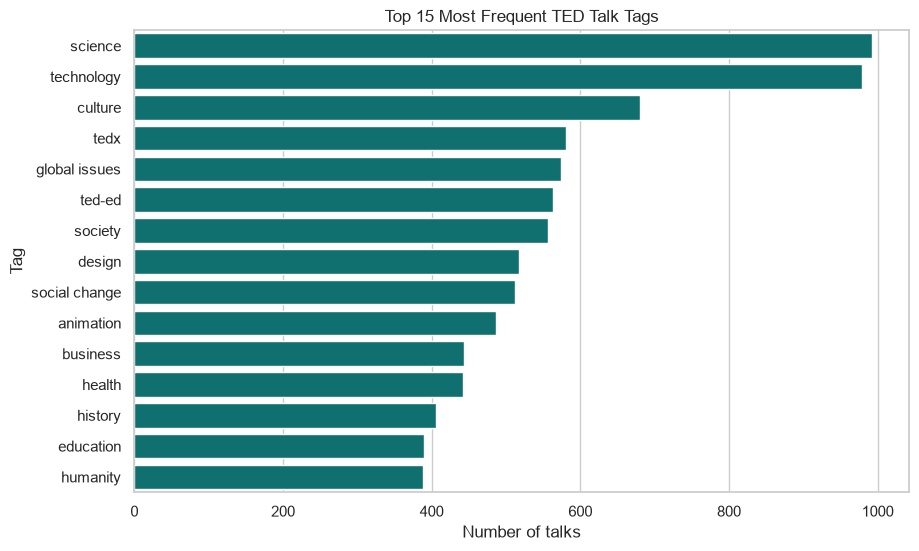

In [14]:
plt.figure(figsize=(10, 6))
sns.barplot(data=top_tags, x="count", y="tag", color="teal")
plt.title("Top 15 Most Frequent TED Talk Tags")
plt.xlabel("Number of talks")
plt.ylabel("Tag")
plt.show()

## Activity 4: Tag and Topic Analysis, Observations

### How the tags are stored and processed
- In the raw file, the `topics` column is stored as a **text string that looks like a Python list**, for example `['alternative energy', 'cars', 'climate change', ...]`. Its type is `str`, not a real list.
- To analyse it, I converted each string into a real list using `ast.literal_eval`, then lowercased the tags and stripped extra spaces. A fallback splits on commas if a value is not in list format.
- The result is saved in a new column, `topics_list`, in my working copy. The original `topics` column and the raw file were not changed.
- Each tag was then counted across all 4005 talks with Python's `Counter`.

### Key numbers
- Total unique tags: **457**
- Talks with zero tags: **0** (every talk has at least one tag)
- Average tags per talk: **7.92**

### Top 15 tags

| Rank | Tag | Talks |
|---|---|---|
| 1 | science | 993 |
| 2 | technology | 979 |
| 3 | culture | 680 |
| 4 | tedx | 581 |
| 5 | global issues | 574 |
| 6 | ted-ed | 563 |
| 7 | society | 557 |
| 8 | design | 518 |
| 9 | social change | 512 |
| 10 | animation | 487 |
| 11 | business | 443 |
| 12 | health | 442 |
| 13 | history | 406 |
| 14 | education | 390 |
| 15 | humanity | 388 |

### Which topics appear most
- **Science (993) and technology (979)** are the clear leaders. Each appears in about a quarter of all talks (roughly 24-25%). Culture comes next with 680 talks (about 17%).
- Many of the top tags are about society: global issues, society, social change, humanity and education.
- `tedx` (581) and `ted-ed` (563) are not subject topics. Looking at sample talks tagged `tedx` (for example "Tribal leadership" and "The post-crisis consumer"), they are ordinary subject talks that carry this tag because they were given at TEDx events. So this tag describes where a talk came from, not what it is about. `ted-ed` appears to work the same way, as a label for the TED-Ed series, though I only checked `tedx` directly.
- Some tags overlap in meaning, for example society / social change / humanity, and global issues / social change.

### Impact on the recommendation system
- Because science and technology are so common, many talks share these tags. If the model matches on tags alone, it may keep recommending science and technology talks, and these two tags will not help separate similar talks.
- Having at least one tag on every talk is good news. Tag-based filtering can work for all 4005 talks.
- With about 8 tags per talk, tags carry a lot of information, so they can be a strong feature alongside the text.
- Format-type tags (`tedx`, `ted-ed`) could cause the model to match talks because they come from the same program, not because they are about the same thing.

### Proposed handling (nothing has been removed)
1. Convert `topics` from a string to a real list (done in `topics_list`) and keep it as a standard step for the cleaning phase.
2. Review `tedx` and `ted-ed`. Consider moving them into a separate "source type" feature, so they don't count as subject topics.
3. Consider down-weighting very common tags (science, technology), for example with TF-IDF weighting, so rarer tags have more influence.
4. Review overlapping tags (society / social change / humanity) and decide whether to group them.
5. Check rare tags (those that appear only once or twice) in the cleaning task, because they add little for matching.

In [15]:
extra_cols = [c for c in ["duration", "views", "comments"] if c in data.columns]
print("Available:", extra_cols)
print("Not available:", [c for c in ["duration", "views", "comments"] if c not in data.columns])
display(data[extra_cols].describe())

Available: ['duration', 'views', 'comments']
Not available: []


,duration,views,comments
count,4005.000000,4.005000e+03,3350.000000
mean,724.011236,2.148006e+06,161.997015
std,361.775462,3.451226e+06,268.838922
min,60.000000,0.000000e+00,0.000000
25%,393.000000,8.820690e+05,38.000000
50%,738.000000,1.375508e+06,89.000000
75%,974.000000,2.133110e+06,188.000000
max,3922.000000,6.505195e+07,6449.000000


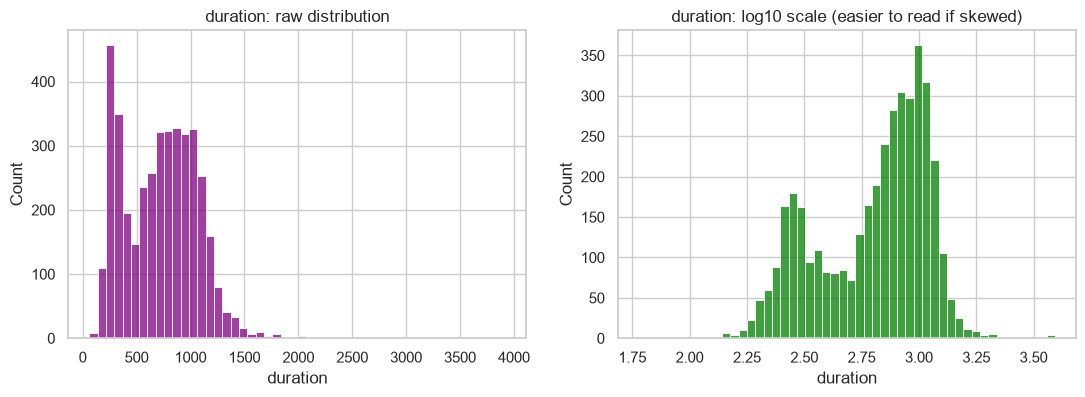

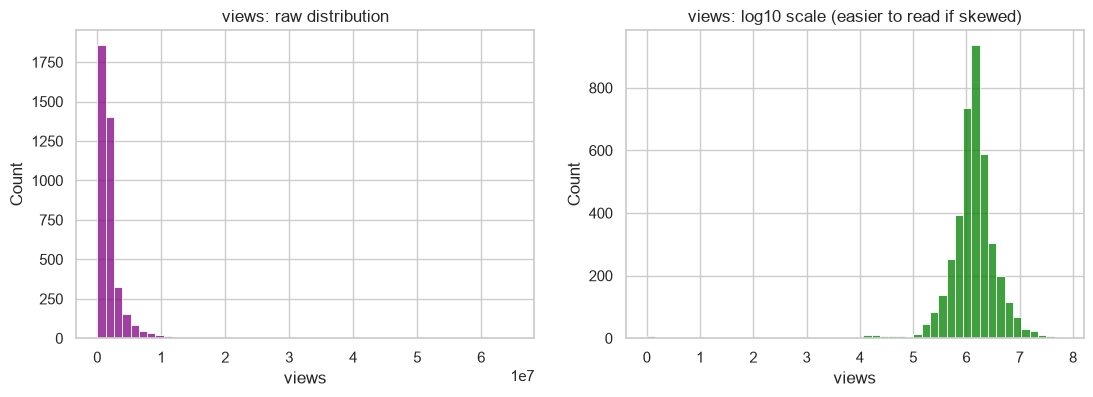

In [16]:
for col in extra_cols[:2]:   # duration and views
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    sns.histplot(data[col], bins=50, ax=ax[0], color="purple")
    ax[0].set_title(f"{col}: raw distribution")
    sns.histplot(np.log10(data[col].clip(lower=1)), bins=50, ax=ax[1], color="green")
    ax[1].set_title(f"{col}: log10 scale (easier to read if skewed)")
    plt.show()

In [17]:
for col in extra_cols:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = data[(data[col] < low) | (data[col] > high)]
    print(f"{col}: {len(outliers)} outliers | zeros: {(data[col] == 0).sum()} | "
          f"min: {data[col].min()} | max: {data[col].max()}")

if "duration" in data.columns:
    display(data.nlargest(3, "duration")[["title", "duration"]])
    display(data.nsmallest(3, "duration")[["title", "duration"]])
if "views" in data.columns:
    display(data.nlargest(3, "views")[["title", "views"]])

duration: 21 outliers | zeros: 0 | min: 60 | max: 3922
views: 393 outliers | zeros: 6 | min: 0 | max: 65051954
comments: 261 outliers | zeros: 2 | min: 0.0 | max: 6449.0


,title,duration
3768,How we can turn the tide on climate,3922
3965,The quest for the coronavirus vaccine,3760
3973,It's OK to feel overwhelmed. Here's what to do...,3740


,title,duration
3623,"""Ode to the Only Black Kid in the Class""",60
3516,"""Three Months After""",78
3554,"""New Colossus""",78


,title,views
4,Do schools kill creativity?,65051954
1296,Your body language may shape who you are,57074270
2062,This is what happens when you reply to spam email,56932551


## Activity 5: Additional Data Analysis (duration, views, comments)

All three columns (`duration`, `views`, `comments`) are available in the dataset.

### Descriptive statistics

| Statistic | duration (seconds) | views | comments |
|---|---|---|---|
| Count | 4005 | 4005 | 3350 |
| Mean | 724.0 | 2,148,006 | 162.0 |
| Median | 738 | 1,375,508 | 89 |
| Std | 361.8 | 3,451,226 | 268.8 |
| Min | 60 | 0 | 0 |
| Max | 3922 | 65,051,954 | 6449 |
| 25% / 75% | 393 / 974 | 882,069 / 2,133,110 | 38 / 188 |

`comments` has a count of 3350 because 655 values are missing (see the missing-value analysis).

### Duration
- The median talk is about 738 seconds (about 12 minutes). Most talks fall between 393 and 974 seconds (about 6.5 to 16 minutes).
- The chart has **two peaks**: one at roughly 5 minutes and another at roughly 13-17 minutes. This matches the two peaks in the transcript-length chart, so the two groups seem to be short talks and full-length talks.
- IQR outliers: **21 talks**, all on the long side. The longest are "How we can turn the tide on climate" (3922 s, about 65 min), "The quest for the coronavirus vaccine" (3760 s) and "It's OK to feel overwhelmed. Here's what to do..." (3740 s). These look like special long-form sessions, not errors.
- The shortest are 60 to 78 seconds, for example "Ode to the Only Black Kid in the Class" (60 s), "Three Months After" (78 s) and "New Colossus" (78 s). These look like very short performances or poems. There are no zero or negative durations.

### Views
- Views are **extremely right-skewed**. The mean (2.15 million) is far higher than the median (1.38 million), and the raw histogram has almost all talks bunched near zero with a very long tail.
- On the log10 scale, the distribution looks roughly bell-shaped around 10^6 (about 1 million views). A log transform makes this column much easier to work with.
- IQR outliers: **393 talks** (about 9.8%). The top three are "Do schools kill creativity?" (65.05 million), "Your body language may shape who you are" (57.07 million) and "This is what happens when you reply to spam email" (56.93 million).
- **6 talks have 0 views**. This is suspicious and needs checking, for example whether they were published very recently or are data errors.

### Comments
- Median 89, mean 162, maximum 6449. The distribution is also right-skewed, with **261 outliers** among the 3350 talks that have a value.
- 2 talks have 0 comments.
- 655 talks (16.35%) have no comment count at all.

### Observations and impact on the recommender
1. Raw views vary enormously. If views are used for popularity ranking, a few mega-hit talks will dominate unless the values are log-transformed or scaled.
2. The views outliers are real, popular talks, not mistakes, so they should be kept (not deleted), but scaled.
3. Duration seems to separate short talks from full-length talks, so it could be a useful feature for filtering ("short talks only").
4. Views are a snapshot taken when the data was collected. Older talks have had more time to collect views, so views may favour older talks. This should be considered if views are used for ranking.

## Summary of Key Findings

1. **The dataset is structurally clean.** It has 4005 talks and 19 columns, with no duplicate rows and no repeated `talk_id`, `url` or `title`, so every talk is unique.
2. **The core recommendation fields are complete.** `title`, `description`, `topics`, `transcript` and `url` have 0 missing or empty values, so text-based and tag-based recommendations can work for every talk.
3. **Missing values are limited to optional columns.** `comments` (16.35%, 655 talks), `occupations` (13.03%, 522) and `about_speakers` (12.56%, 503) have the most gaps. `all_speakers` (4) and `recorded_date` (1) are almost complete.
4. **Transcript length varies a lot and has two peaks.** The median is 1753 words (range 2 to 11,121), with peaks around 600-700 and 2000 words. The two peaks match the two duration peaks (about 5 min and about 15 min).
5. **A small number of talks have very little text.** 28 transcripts are under 200 words (shortest 2 to 4 words), and they are mostly music, dance or magic performances. 1 description is under 10 words.
6. **Descriptions are consistent.** Most are 40 to 80 words (median 57), with none empty, so they are a reliable second text source.
7. **Tags are available for every talk but stored as text.** `topics` is a string that looks like a list, with 457 unique tags and about 7.92 tags per talk. Science (993) and technology (979) dominate.
8. **Some tags describe the program, not the subject.** `tedx` (581) and `ted-ed` (563) are in the top 6, and could mislead a tag-based model.
9. **Views are extremely skewed.** The median is 1.38 million but the maximum is 65 million, with 393 outliers. 6 talks have 0 views.
10. **Duration is generally reasonable.** There are no zero durations, 21 long outliers (up to 65 minutes), and the shortest talks are about 1 minute long.

## Proposed Data-Cleaning Plan

Nothing has been deleted or changed in this notebook. The raw file in `data/raw/` is untouched. These are the actions proposed for Task 3.

| # | Issue | Evidence | Why it matters | Proposed fix |
|---|---|---|---|---|
| 1 | `topics` stored as a string | The first value is a string that looks like a list, not a real list | The model can't use tags until they are converted | Convert to a real list (`ast.literal_eval`) and keep the original column |
| 2 | Program-type tags mixed with subject tags | `tedx` (581), `ted-ed` (563) are in the top 6 | Talks could match because of the same program, not the same subject | Move these into a separate "source type" feature, or exclude them from topic matching |
| 3 | Very common tags dominate | science (993), technology (979) | These tags make many talks look similar | Down-weight them (for example TF-IDF weighting) |
| 4 | Overlapping and rare tags | 457 unique tags; society, social change and humanity overlap | Rare or duplicate-meaning tags add noise | Review rare tags (appearing once or twice) and consider grouping similar ones |
| 5 | Very short transcripts | 28 talks under 200 words (shortest 2 words) | Too little text for reliable text similarity | Keep them, add a `short_transcript` flag, and rely on title, description and tags for these talks |
| 6 | Short description | 1 description under 10 words | Minor effect | Keep, and rely on the transcript and tags |
| 7 | Missing `comments` | 655 talks (16.35%) | Can bias popularity features if filled with 0 | Don't fill with 0. Use the median plus a `comments_missing` flag, or leave out of the model |
| 8 | Missing speaker details | `occupations` 522, `about_speakers` 503 | Optional features only | Fill with "Unknown" |
| 9 | Missing `all_speakers` and `recorded_date` | 4 and 1 talks | Very small effect | Fill `all_speakers` from `speaker_1`; check the 1 date row manually |
| 10 | Zero-view talks | 6 talks with 0 views | May be data errors or very new talks | Check their `published_date` and decide whether to keep, flag or exclude them |
| 11 | Heavily skewed views and comments | Views: median 1.38 million vs max 65 million | A few talks would dominate any popularity ranking | Apply a log transform or scaling; keep the outliers because they are real |
| 12 | Long and short duration outliers | 21 duration outliers (up to 3922 s) | Mostly genuine special formats | Keep, but consider a `duration_group` feature (short / medium / long) |
| 13 | Text columns need preprocessing | Raw transcript and description text | Needed for ML | In Task 3: lowercase, remove punctuation and stop words, then combine title + description + transcript into one text field |
| 14 | Duplicates | None found | No action needed | Re-check after cleaning to be sure none were introduced |
| 15 | Dictionary and list columns stored as text | `all_speakers` and `related_talks` look like `{0: 'Al Gore'}`; `available_lang` looks like `['ar', 'bg']` | They can't be used as structured data until parsed | Parse with `ast.literal_eval` in Task 3 if these features are needed |